# 01 — Первичный анализ данных

Датасет — соревнование Kaggle от Альфа-Банка по кредитному скорингу. Единица данных —
**заявка**, а `flag` — дефолт по заявке. К каждой заявке приложена
**кредитная история**: несколько строк, по одной на каждый кредитный продукт.

Данные лежат в `data/raw/data_for_competition/`: 12 parquet-партиций train, 2 партиции
test, файл цели `train_target.csv`, словарь `description.xlsx` и `sample_submission.csv`.
Сами данные не грузятся целиком: проверки идут потоково — **одна партиция в памяти
за раз**, а там, где нужен график, берётся выборка, и это прямо сказано в тексте.

Первый аналитический ноутбук после `00-setup`; данные готовит `00`. Читается по порядку номеров:
`01-eda` (этот) → `02-baseline` → `03-feature-analysis` → `04-features-training`.

Задача этого шага — понять **форму данных и границы применимости чисел**, а не измерить
силу признаков: сила связи и отбор схемы обучения — предмет раздела `03`.

1. словарь данных и природа полей;
2. базовые проверки: пропуски, дубликаты, полнота цели;
3. дисбаланс классов и его устойчивость по времени;
4. границы и распределения train против test;
5. почему классические «выбросы» здесь не работают;
6. из чего следует, как учить модель.

In [1]:
import gc
import resource
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq

STARTED = time.perf_counter()


def find_repo_root() -> Path:
    """Корень репозитория ищем по pyproject.toml: ноутбук работает из любого каталога внутри репозитория."""
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise RuntimeError("не найден корень репозитория: pyproject.toml отсутствует вверх по дереву")


def part_key(path: Path) -> int:
    """Номер партиции из имени файла — чтобы порядок не зависел от лексикографии."""
    return int("".join(character for character in path.stem if character.isdigit()))


def peak_memory_gb() -> float:
    """Пик RSS процесса. macOS отдаёт байты, Linux — кибибайты."""
    peak = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
    return peak / 2**30 if sys.platform == "darwin" else peak / 2**20


def add_counts(total: np.ndarray | None, counts: np.ndarray) -> np.ndarray:
    """Поэлементная сумма двух гистограмм уровней: длину выравниваем по большей."""
    if total is None:
        return counts
    if len(counts) > len(total):
        total = np.pad(total, (0, len(counts) - len(total)))
    total[: len(counts)] += counts
    return total


def fmt(number: int) -> str:
    """Тысячи разделяем пробелом: числа форматируются одинаково во всех выводах."""
    return f"{number:,}".replace(",", " ")


REPO_ROOT = find_repo_root()
DATA_DIR = REPO_ROOT / "data" / "raw" / "data_for_competition"
TRAIN_PARTS = sorted((DATA_DIR / "train_data").glob("*.pq"), key=part_key)
TEST_PARTS = sorted((DATA_DIR / "test_data").glob("*.pq"), key=part_key)
DESCRIPTION = DATA_DIR / "description.xlsx"
TRAIN_TARGET = DATA_DIR / "train_target.csv"
TEST_TARGET = DATA_DIR / "test_target.csv"

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

print(f"корень:        {REPO_ROOT.name}")
print(f"данные:        {DATA_DIR.relative_to(REPO_ROOT)}")
print(f"train-партиций: {len(TRAIN_PARTS)}, test-партиций: {len(TEST_PARTS)}")

корень:        kaggle-creditscore-alfa
данные:        data/raw/data_for_competition
train-партиций: 12, test-партиций: 2


## Словарь данных

`description.xlsx` — единственный источник, который говорит, **что означают коды**.
Это определяет дальнейший разбор: два листа (`deals` и `features`) и две сноски про кодирование
превращают часть числовых колонок в ярлыки, которые нельзя ни усреднять, ни сравнивать.

In [2]:
book = pd.ExcelFile(DESCRIPTION)
deals = pd.read_excel(DESCRIPTION, sheet_name="deals")
features = pd.read_excel(DESCRIPTION, sheet_name="features")

print(f"листы словаря: {book.sheet_names}")
print("\nлист deals — что такое строка и цель:")
print(deals.to_string(index=False))

notes = features["Поле"].dropna().astype(str)
notes = notes[notes.str.startswith(("*", "**"))]
print("\nсноски про кодирование:")
for note in notes:
    print("  •", " ".join(note.split()))

DATA_COLUMNS = list(pq.ParquetFile(TRAIN_PARTS[0]).schema_arrow.names)
FEATURES = [name for name in DATA_COLUMNS if name != "id"]

groups = [
    ("id", ["id"], "заявка; нумерация по дате — больший номер это более поздняя заявка"),
    ("rn", ["rn"], "номер кредитного продукта в истории заявки; осмысленный код"),
    ("pre_*", [n for n in DATA_COLUMNS if n.startswith("pre_")],
     "интервалы, каждому случайно присвоен номер (сноска *)"),
    ("enc_*", [n for n in DATA_COLUMNS if n.startswith("enc_")],
     "категории, каждой случайно присвоен номер (сноска **)"),
    ("is_zero_*", [n for n in DATA_COLUMNS if n.startswith("is_zero_")],
     "флаги «величина равна нулю»; осмысленный код 0/1"),
    ("pclose_flag, fclose_flag", ["pclose_flag", "fclose_flag"],
     "флаги «дата закрытия не определена»; осмысленный код 0/1"),
    ("flag", ["flag"], "целевая переменная: 1 — дефолт; лежит в train_target.csv, не в партициях"),
]
rows = [
    {"группа": pattern, "колонок": len(members), "пример": ", ".join(members[:3]) or "—", "смысл": meaning}
    for pattern, members, meaning in groups
]
print("\nгруппы полей:")
print(pd.DataFrame(rows).to_string(index=False))

hashed_features = [name for name in FEATURES if name.startswith(("pre_", "enc_"))]
meaningful_features = [name for name in FEATURES if name not in hashed_features]
print(f"\nпризнаков всего: {len(FEATURES)}; со случайной нумерацией: {len(hashed_features)} "
      f"(все pre_* и enc_*); с осмысленным кодом: {len(meaningful_features)} -> {meaningful_features}")

# В словаре есть имена вида is_zero_loans_5, в данных — is_zero_loans5. Проверяем, что
# расхождение только в лишнем подчёркивании перед цифрой, а не в смысле.
documented = {
    name.strip() for name in features["Поле"].dropna().astype(str) if not name.strip().startswith("*")
}
literal_missing = sorted(documented - set(DATA_COLUMNS))
normalized = {column.replace("_", "") for column in DATA_COLUMNS}
renamed = sorted(name for name in literal_missing if name.replace("_", "") in normalized)
unresolved = sorted(name for name in literal_missing if name.replace("_", "") not in normalized)
print(f"\nимён словаря, которых нет в данных дословно: {len(literal_missing)}")
print(f"  из них совпадают после удаления подчёркиваний ({len(renamed)}): {renamed}")
print(f"  не сопоставлено вовсе ({len(unresolved)}): {unresolved} — это шаблон enc_paym_{{0..N}}, а не имя")

листы словаря: ['deals', 'features']

лист deals — что такое строка и цель:
Имя признака                                                                                                   Описание 
          id Идентификатор заявки. Заявки пронумерованы так, что более поздним заявкам соответствует более поздняя дата.
        flag                       Целевая переменная, 1 – факт ухода в дефолт. Доступна участникам в обучающей выборке.

сноски про кодирование:
  • * область значений поля разбивается на N непересекающихся промежутков, каждому промежутку случайным образом ставится в соответствие уникальный номер от 0 до N-1, значение поля заменяется номером промежутка, которому оно принадлежит
  • ** каждому уникальному значению поля случайным образом ставится в соответствие уникальный номер от 0 до K, значение поля заменяется номером этого значения

группы полей:
                  группа  колонок                                              пример                                         

### Как выглядит одна партиция

Форму и размер берём из метаданных parquet, три строки — из потокового чтения:
целиком ни одна партиция на 61 колонку в память не поднимается. Ограничение по памяти существенно:
собранный train весит около 6 ГБ в `int32`, а партиция целиком — около гигабайта.

In [3]:
part = TRAIN_PARTS[0]
part_file = pq.ParquetFile(part)
meta = part_file.metadata
schema = part_file.schema_arrow
display_columns = ["id", "rn", "pre_util", "pre_over2limit", "enc_loans_credit_type", "pclose_flag"]

print(f"{part.name}: {fmt(meta.num_rows)} строк, {meta.num_columns} колонок")
print(f"партиция целиком: около {meta.num_rows * meta.num_columns * 8 / 2**30:.2f} ГБ (все колонки int64)")
print("типы колонок:")
print(pd.Series([str(type_) for type_ in schema.types]).value_counts().rename_axis("тип").to_frame("колонок").to_string())

head = next(part_file.iter_batches(batch_size=3, columns=display_columns)).to_pandas()
print("\nтри строки (часть колонок для читаемости):")
print(head.to_string(index=False))
print("\nвсе значения — целые числа: это либо счётчики, либо номера уровней")

train_data_0.pq: 1 974 724 строк, 61 колонок
партиция целиком: около 0.90 ГБ (все колонки int64)
типы колонок:
       колонок
тип           
int64       61

три строки (часть колонок для читаемости):
 id  rn  pre_util  pre_over2limit  enc_loans_credit_type  pclose_flag
  0   1        16               2                      4            0
  0   2        16               2                      4            0
  0   3        15               2                      3            1

все значения — целые числа: это либо счётчики, либо номера уровней


## Базовые проверки: пропуски и дубликаты

Прежде чем что-то считать, проверяем полноту данных. Идём по 12 партициям
по одной и **читаем каждую партицию батчами по 250 тысяч строк**: у каждого батча
берём пропуски, максимум `rn` и кодируем пару `(id, rn)` в одно число `id * 1000 + rn`.
Максимум `rn` измеряем здесь же, чтобы кодировка была однозначной:
константа 1000 обязана его превышать. Проверка находит повторяющиеся пары `(id, rn)`, а в памяти
одновременно лежит около 200 МБ, а не 26 млн строк.

In [4]:
RN_BASE = 1000
BATCH_ROWS = 250_000
null_by_column = pd.Series(0, index=DATA_COLUMNS, dtype="int64")
pair_parts: list[np.ndarray] = []
part_rows = []
rn_max = 0
for part_path in TRAIN_PARTS:
    rows = 0
    part_nulls = 0
    for batch in pq.ParquetFile(part_path).iter_batches(batch_size=BATCH_ROWS):
        block = batch.to_pandas()
        nulls = block.isna().sum()
        null_by_column = null_by_column.add(nulls, fill_value=0).astype("int64")
        part_nulls += int(nulls.sum())
        rn_max = max(rn_max, int(block["rn"].max()))
        pair_parts.append(block["id"].to_numpy() * RN_BASE + block["rn"].to_numpy())
        rows += len(block)
        del block, nulls
    part_rows.append({"файл": part_path.name, "строк": rows, "пропусков": part_nulls})
    gc.collect()

print("партиции train:")
print(pd.DataFrame(part_rows).to_string(index=False))
print(f"\nстрок всего: {fmt(sum(row['строк'] for row in part_rows))}")
print(f"максимум rn в train: {rn_max} — меньше RN_BASE = {RN_BASE}, поэтому id * 1000 + rn однозначен")
assert rn_max < RN_BASE

pairs = np.concatenate(pair_parts)
pair_parts.clear()
pairs.sort()
duplicate_pairs = int((pairs[1:] == pairs[:-1]).sum())
del pairs
gc.collect()

print(f"\nвсего пропусков в train: {int(null_by_column.sum())}")
columns_with_nulls = null_by_column[null_by_column > 0]
print(f"колонок хотя бы с одним пропуском: {len(columns_with_nulls)}"
      + (f" -> {list(columns_with_nulls.index)}" if len(columns_with_nulls) else ""))
print(f"дубликатов (id, rn): {duplicate_pairs}")
print(f"всего колонок: {len(DATA_COLUMNS)}; признаков (без id): {len(FEATURES)}")

партиции train:
            файл   строк  пропусков
 train_data_0.pq 1974724          0
 train_data_1.pq 2107305          0
 train_data_2.pq 2080508          0
 train_data_3.pq 2112592          0
 train_data_4.pq 2064110          0
 train_data_5.pq 2150908          0
 train_data_6.pq 2176452          0
 train_data_7.pq 2222245          0
 train_data_8.pq 2242615          0
 train_data_9.pq 2284256          0
train_data_10.pq 2296372          0
train_data_11.pq 2450630          0

строк всего: 26 162 717
максимум rn в train: 58 — меньше RN_BASE = 1000, поэтому id * 1000 + rn однозначен



всего пропусков в train: 0
колонок хотя бы с одним пропуском: 0
дубликатов (id, rn): 0
всего колонок: 61; признаков (без id): 60


In [5]:
train_target = pd.read_csv(TRAIN_TARGET)
test_target = pd.read_csv(TEST_TARGET)

flag_counts = train_target["flag"].value_counts().sort_index()
print("train_target.csv:")
print(
    pd.DataFrame(
        {
            "строк": [len(train_target)],
            "id уникален": [train_target["id"].is_unique],
            "id монотонен": [train_target["id"].is_monotonic_increasing],
            "id min": [int(train_target["id"].min())],
            "id max": [int(train_target["id"].max())],
        }
    ).to_string(index=False)
)
print("\nбаланс цели на заявках:")
print(
    pd.DataFrame(
        {
            "flag": flag_counts.index,
            "заявок": flag_counts.values,
            "доля": (flag_counts / len(train_target)).round(4).values,
        }
    ).to_string(index=False)
)
BASE_RATE = float(train_target["flag"].mean())
print(f"\nдоля flag=1: {BASE_RATE:.4f} ({fmt(int(flag_counts.get(1, 0)))} из {fmt(len(train_target))})")

train_target.csv:
  строк  id уникален  id монотонен  id min  id max
3000000         True          True       0 2999999

баланс цели на заявках:
 flag  заявок   доля
    0 2893558 0.9645
    1  106442 0.0355

доля flag=1: 0.0355 (106 442 из 3 000 000)


## Дисбаланс классов

Целевая переменная редкая: положительных примерно одна из двадцати восьми заявок.
ROC AUC не зависит от баланса классов, но доля `flag=1` на малых срезах
нестабильна. И она **не постоянна во времени**: заявки
`id` пронумерованы по дате, поэтому раскладываем заявки на 20 корзин `id` и смотрим
долю в каждой.

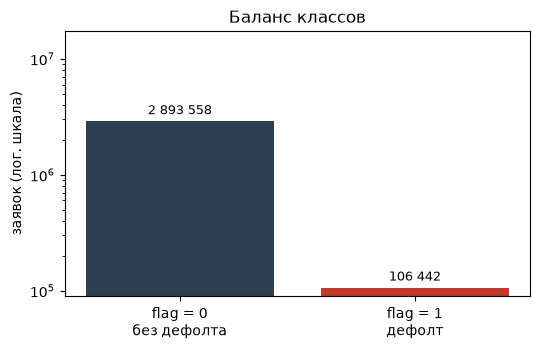

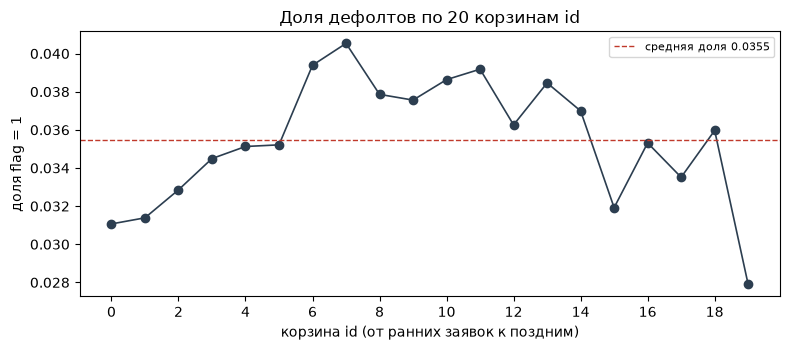

доля flag=1 по корзинам id: min 0.0279, max 0.0405, средняя 0.0355
разброс не нулевой: от 0.028 до 0.041 — доля зависит от времени заявки, но меняется в узких пределах


In [6]:
id_values = train_target["id"].to_numpy()
flag_values = train_target["flag"].to_numpy()
bin_index = id_values * 20 // (id_values.max() + 1)  # 20 временных срезов по id
bin_counts = np.bincount(bin_index, minlength=20)
bin_rate = np.bincount(bin_index, weights=flag_values, minlength=20) / bin_counts

figure, axis = plt.subplots(figsize=(5.5, 3.6))
axis.bar(flag_counts.index, flag_counts.values, color=["#2c3e50", "#c0392b"])
axis.set_yscale("log")
axis.set_ylim(top=flag_counts.max() * 6)
axis.set_xticks([0, 1])
axis.set_xticklabels(["flag = 0\nбез дефолта", "flag = 1\nдефолт"])
axis.set_ylabel("заявок (лог. шкала)")
axis.set_title("Баланс классов")
for position, value in zip([0, 1], flag_counts.values, strict=True):
    axis.text(position, value * 1.15, fmt(int(value)), ha="center", fontsize=9)
figure.tight_layout()
plt.show()

figure, axis = plt.subplots(figsize=(8, 3.6))
positions = np.arange(20)
axis.plot(positions, bin_rate, marker="o", color="#2c3e50", linewidth=1.2)
axis.axhline(BASE_RATE, color="#c0392b", linestyle="--", linewidth=1, label=f"средняя доля {BASE_RATE:.4f}")
axis.set_xticks(positions[::2])
axis.set_xlabel("корзина id (от ранних заявок к поздним)")
axis.set_ylabel("доля flag = 1")
axis.set_title("Доля дефолтов по 20 корзинам id")
axis.legend(fontsize=8)
figure.tight_layout()
plt.show()

print(f"доля flag=1 по корзинам id: min {bin_rate.min():.4f}, max {bin_rate.max():.4f}, "
      f"средняя {bin_rate.mean():.4f}")
print(f"разброс не нулевой: от {bin_rate.min():.3f} до {bin_rate.max():.3f} — "
      "доля зависит от времени заявки, но меняется в узких пределах")

## Train и test

Заявки пронумерованы по дате, поэтому train и test — это не случайное разбиение, а
**два отрезка времени**. Проверяем границу: диапазоны `id` не должны пересекаться,
иначе одна и та же заявка попала бы и в обучение, и в проверку. Доли уровней
сравниваем на выборке, действительно примыкающей к границе: **последние 2
train-партиции** (они соседствуют с test по времени) и обе test-партиции.

границы id и размеры выборок:
выборка  заявок  id min  id max  партиций
  train 3000000       0 2999999        12
   test  500000 3000000 3499999         2

строк истории: train — 26 162 717, test — 4 724 601

пересечение train и test по id: 0
(train: 3 000 000 заявок по порядку, затем test: 500 000 — граница хронологическая)
id в test_target уникален: True — это условие для проверки пересечения выше


полнота target↔history: train — 3 000 000 заявок, test — 500 000; множества id совпадают с target


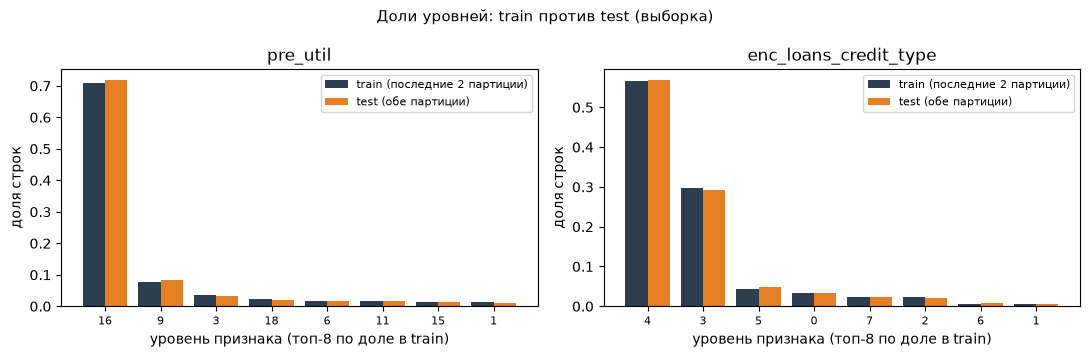

pre_util: уровней 20, максимальная разница долей 0.0099
enc_loans_credit_type: уровней 8, максимальная разница долей 0.0055

доли близки, но не идентичны: это ожидаемо для соседних отрезков времени
один ли у train и test словарь уровней — отдельная проверка в 03


In [7]:
train_min, train_max = int(train_target["id"].min()), int(train_target["id"].max())
test_min, test_max = int(test_target["id"].min()), int(test_target["id"].max())
overlap = np.intersect1d(id_values, test_target["id"].to_numpy(), assume_unique=True)

print("границы id и размеры выборок:")
print(
    pd.DataFrame(
        {
            "выборка": ["train", "test"],
            "заявок": [len(train_target), len(test_target)],
            "id min": [train_min, test_min],
            "id max": [train_max, test_max],
            "партиций": [len(TRAIN_PARTS), len(TEST_PARTS)],
        }
    ).to_string(index=False)
)

train_rows = sum(pq.ParquetFile(path).metadata.num_rows for path in TRAIN_PARTS)
test_rows = sum(pq.ParquetFile(path).metadata.num_rows for path in TEST_PARTS)
print(f"\nстрок истории: train — {fmt(train_rows)}, test — {fmt(test_rows)}")

print(f"\nпересечение train и test по id: {len(overlap)}")
print(f"(train: {fmt(train_max + 1)} заявок по порядку, затем test: {fmt(len(test_target))} — "
      "граница хронологическая)")
print(f"id в test_target уникален: {test_target['id'].is_unique} — это условие для проверки пересечения выше")
assert test_target["id"].is_unique
assert test_target["id"].is_monotonic_increasing

train_history_ids = np.concatenate([
    np.unique(pd.read_parquet(path, columns=["id"])["id"].to_numpy())
    for path in TRAIN_PARTS
])
assert len(train_history_ids) == 3_000_000
assert np.array_equal(np.sort(train_history_ids), train_target["id"].to_numpy())

test_history_ids = np.concatenate([
    np.unique(pd.read_parquet(path, columns=["id"])["id"].to_numpy())
    for path in TEST_PARTS
])
assert len(test_history_ids) == 500_000
assert np.array_equal(np.sort(test_history_ids), test_target["id"].to_numpy())

print(f"полнота target↔history: train — {fmt(len(train_history_ids))} заявок, "
      f"test — {fmt(len(test_history_ids))}; множества id совпадают с target")
del train_history_ids, test_history_ids
gc.collect()

COMPARE = ["pre_util", "enc_loans_credit_type"]
SAMPLE_TRAIN = TRAIN_PARTS[-2:]  # последние партиции train примыкают к test по времени
train_levels = {name: None for name in COMPARE}
test_levels = {name: None for name in COMPARE}
for part_path in SAMPLE_TRAIN:
    sample = pd.read_parquet(part_path, columns=COMPARE)
    for name in COMPARE:
        train_levels[name] = add_counts(train_levels[name], np.bincount(sample[name].to_numpy()))
    del sample
for part_path in TEST_PARTS:
    sample = pd.read_parquet(part_path, columns=COMPARE)
    for name in COMPARE:
        test_levels[name] = add_counts(test_levels[name], np.bincount(sample[name].to_numpy()))
    del sample
gc.collect()

figure, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for axis, name in zip(axes, COMPARE, strict=True):
    train_counts, test_counts = train_levels[name], test_levels[name]
    width = max(len(train_counts), len(test_counts))
    train_counts = np.pad(train_counts, (0, width - len(train_counts)))
    test_counts = np.pad(test_counts, (0, width - len(test_counts)))
    top = np.argsort(-train_counts)[:8]
    positions = np.arange(len(top))
    axis.bar(positions - 0.2, train_counts[top] / train_counts.sum(), width=0.4,
             color="#2c3e50", label="train (последние 2 партиции)")
    axis.bar(positions + 0.2, test_counts[top] / test_counts.sum(), width=0.4,
             color="#e67e22", label="test (обе партиции)")
    axis.set_xticks(positions)
    axis.set_xticklabels([f"{level}" for level in top], fontsize=8)
    axis.set_xlabel("уровень признака (топ-8 по доле в train)")
    axis.set_ylabel("доля строк")
    axis.set_title(name)
    axis.legend(fontsize=8)
figure.suptitle("Доли уровней: train против test (выборка)", fontsize=11)
figure.tight_layout()
plt.show()

for name in COMPARE:
    train_counts, test_counts = train_levels[name], test_levels[name]
    width = max(len(train_counts), len(test_counts))
    train_share = np.pad(train_counts, (0, width - len(train_counts))) / train_counts.sum()
    test_share = np.pad(test_counts, (0, width - len(test_counts))) / test_counts.sum()
    print(f"{name}: уровней {int((train_counts > 0).sum())}, максимальная разница долей "
          f"{np.abs(train_share - test_share).max():.4f}")
print("\nдоли близки, но не идентичны: это ожидаемо для соседних отрезков времени")
print("один ли у train и test словарь уровней — отдельная проверка в 03")

## Почему «выбросов» здесь нет

Для 49 из 60 признаков (81.7%), закодированных **случайными номерами интервалов**
(сноска `*`) или **категорий** (сноска `**`), `describe()` и IQR-выбросы
неинформативны. Среднее и квантили по таким колонкам усредняют ярлыки, а «выброс»
вида `pre_util = 19` — это не редкий большой остаток, а редкий интервал, которому
случайно достался номер 19.

**Код — это ярлык, а не число.** Поэтому для модели допустимы one-hot и target
encoding (сглаженный логарифм шансов `flag` для уровня). Target encoding должен
считаться **out-of-fold**, иначе получится утечка. Средние и экстремумы тоже
считаем по target-encoded значениям, а не по сырым кодам.

Что здесь можно измерить: **длину кредитной истории заявки** (число записей).
Считаем её на выборке: первые 2 партиции train из 12.


история на выборке (2 партиции): 500 000 заявок
записей на заявку: медиана 7, среднее 8.16, максимум 51, доля заявок с одной записью 0.0770


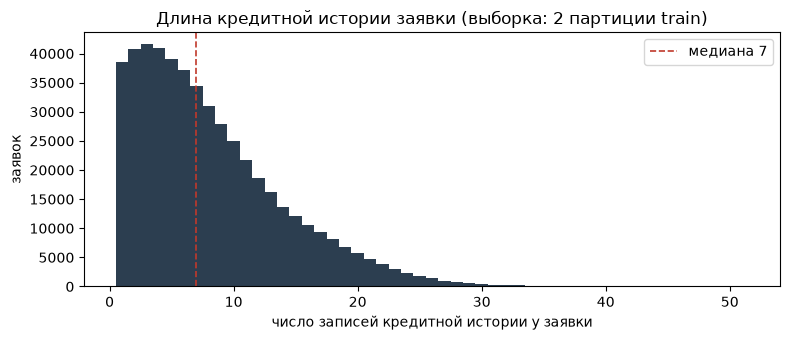

In [8]:
application_records = []
for part_path in TRAIN_PARTS[:2]:
    sample = pd.read_parquet(part_path, columns=["id"])
    _, counts = np.unique(sample["id"].to_numpy(), return_counts=True)
    application_records.append(counts)
    del sample
gc.collect()
records = np.concatenate(application_records)
application_records.clear()

median_records = float(np.median(records))
print(f"история на выборке (2 партиции): {fmt(len(records))} заявок")
print(f"записей на заявку: медиана {median_records:.0f}, среднее {records.mean():.2f}, "
      f"максимум {records.max()}, доля заявок с одной записью {(records == 1).mean():.4f}")

figure, axis = plt.subplots(figsize=(8, 3.5))
axis.hist(records, bins=np.arange(0.5, records.max() + 1.5, 1), color="#2c3e50")
axis.axvline(median_records, color="#c0392b", linestyle="--", linewidth=1.2,
             label=f"медиана {median_records:.0f}")
axis.set_xlabel("число записей кредитной истории у заявки")
axis.set_ylabel("заявок")
axis.set_title("Длина кредитной истории заявки (выборка: 2 партиции train)")
axis.legend()
figure.tight_layout()
plt.show()

## Природа данных → как будем учить

Из формы данных следуют три решения для следующих ноутбуков.

- **Ярлыки нельзя сравнивать.** Номер уровня — случайный ярлык, поэтому `pre_util = 7`
  не «больше», чем `pre_util = 2`. Код нельзя подставлять как число: в проекте
  используется кодировка через цель (сглаженный логарифм шансов `flag` для уровня);
  one-hot используется в бейзлайне `02`.
- **Строк истории много, заявка одна.** В train 26,16 млн записей на 3 млн заявок,
  а `flag` константен внутри заявки. Значит, строки нужно **агрегировать к заявке**
  (последняя запись, средние, экстремумы), иначе строки с длинной историей получат
  больший вес, чем заявки с короткой. `id` — это заявка; отдельного id, общего для
  нескольких заявок, в данных нет, поэтому связи между заявками не проверяются.
- **Время — не перемешиваем.** Заявки пронумерованы по дате, `id` растёт вместе с
  датой, train и test — соседние отрезки. Валидация должна быть **по времени**
  (блоками `id`), случайное разбиение перемешало бы прошлое с будущим.

Последний график может ввести в заблуждение. `pre_over2limit` при чтении по
строкам даёт широкий разброс долей `flag=1` по уровням. Ниже это измерено на
выборке; почему разброс не переносится на уровень заявки — разбор в `03`.

pre_over2limit, выборка: 4 082 029 строк, уровней 20
строчная база flag=1: 0.0294 (119 931 из 4 082 029 строк)
база заявок: 0.0319 (15 946 из 500 000 заявок)
разброс доли flag=1 по всем уровням: 0.1084
по уровням от 2000 строк: 0.0753 (3 уровня, 4 079 371 строк)
остальные 17 уровней держат 2 658 строк (0.0651%), самый редкий — 66 строк
уровень 17: 2 982 строк, доля flag=1 0.1033 — отдельная подгруппа, не общий тренд


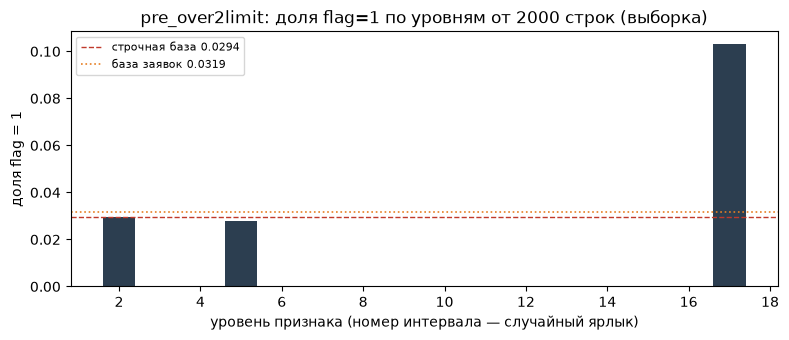


разброс по редким уровням не равен сигналу: строки взвешены историей заявки, а не заявками
после порога 2000 остаётся часть разброса; уровень 17 — отдельная подгруппа
на уровне заявок mean_pre_over2limit даёт AUC около 0.5207 (03) — слабый сигнал, а не его отсутствие
численный ориентир нижней планки даст бейзлайн в 02-baseline


In [9]:
MIN_LEVEL_ROWS = 2000
target_id = train_target["id"].to_numpy()
target_flag = train_target["flag"].to_numpy()
trap_counts, trap_positives = None, None
sample_applications = 0
sample_application_positives = 0
for part_path in TRAIN_PARTS[:2]:
    sample = pd.read_parquet(part_path, columns=["id", "pre_over2limit"])
    app_ids = pd.unique(sample["id"].to_numpy())
    app_flags = target_flag[np.searchsorted(target_id, app_ids)]
    sample_applications += len(app_ids)
    sample_application_positives += int(app_flags.sum())

    row_flag = target_flag[np.searchsorted(target_id, sample["id"].to_numpy())]
    values = sample["pre_over2limit"].to_numpy()
    counts = np.bincount(values)
    positives = np.bincount(values, weights=row_flag, minlength=len(counts))
    trap_counts = add_counts(trap_counts, counts)
    trap_positives = add_counts(trap_positives, positives)
    del sample, row_flag, values, app_ids, app_flags
gc.collect()

row_base = float(trap_positives.sum() / trap_counts.sum())
application_base = sample_application_positives / sample_applications
visible = trap_counts > 0
rates = trap_positives[visible] / trap_counts[visible]
levels = np.flatnonzero(visible)
frequent = trap_counts[visible] >= MIN_LEVEL_ROWS
shown_levels = levels[frequent]
shown_rates = rates[frequent]
rare_rows = int(trap_counts.sum()) - int(trap_counts[shown_levels].sum())

print(f"pre_over2limit, выборка: {fmt(int(trap_counts.sum()))} строк, уровней {len(levels)}")
print(f"строчная база flag=1: {row_base:.4f} "
      f"({fmt(int(trap_positives.sum()))} из {fmt(int(trap_counts.sum()))} строк)")
print(f"база заявок: {application_base:.4f} "
      f"({fmt(sample_application_positives)} из {fmt(sample_applications)} заявок)")
print(f"разброс доли flag=1 по всем уровням: {rates.max() - rates.min():.4f}")
print(f"по уровням от {MIN_LEVEL_ROWS} строк: {shown_rates.max() - shown_rates.min():.4f} "
      f"({len(shown_levels)} уровня, {fmt(int(trap_counts[shown_levels].sum()))} строк)")
print(f"остальные {len(levels) - len(shown_levels)} уровней держат {fmt(rare_rows)} строк "
      f"({rare_rows / trap_counts.sum():.4%}), самый редкий — {fmt(int(trap_counts[visible].min()))} строк")
if 17 in levels:
    level_17 = int(np.flatnonzero(levels == 17)[0])
    print(f"уровень 17: {fmt(int(trap_counts[17]))} строк, доля flag=1 "
          f"{trap_positives[17] / trap_counts[17]:.4f} — отдельная подгруппа, не общий тренд")

figure, axis = plt.subplots(figsize=(8, 3.5))
axis.bar(shown_levels, shown_rates, color="#2c3e50")
axis.axhline(row_base, color="#c0392b", linestyle="--", linewidth=1,
             label=f"строчная база {row_base:.4f}")
axis.axhline(application_base, color="#e67e22", linestyle=":", linewidth=1.2,
             label=f"база заявок {application_base:.4f}")
axis.set_xlabel("уровень признака (номер интервала — случайный ярлык)")
axis.set_ylabel("доля flag = 1")
axis.set_title(f"pre_over2limit: доля flag=1 по уровням от {MIN_LEVEL_ROWS} строк (выборка)")
axis.legend(fontsize=8)
figure.tight_layout()
plt.show()

print("\nразброс по редким уровням не равен сигналу: строки взвешены историей заявки, а не заявками")
print(f"после порога {MIN_LEVEL_ROWS} остаётся часть разброса; уровень 17 — отдельная подгруппа")
print("на уровне заявок mean_pre_over2limit даёт AUC около 0.5207 (03) — слабый сигнал, а не его отсутствие")
print("численный ориентир нижней планки даст бейзлайн в 02-baseline")


In [10]:
elapsed = time.perf_counter() - STARTED
print(f"пик памяти процесса: {peak_memory_gb():.2f} ГБ")
print(f"время прогона: {elapsed / 60:.1f} мин ({elapsed:.0f} с)")

пик памяти процесса: 1.43 ГБ
время прогона: 0.1 мин (6 с)


## Итог

1. **Форма.** 12 train-партиций и 2 test-партиции по 61 колонке; 26,16 млн строк
   истории на 3 000 000 заявок train и 4,72 млн строк на 500 000 заявок test.
2. **Полнота.** Пропусков — 0, дубликатов `(id, rn)` — 0; `id` в
   `train_target.csv` уникален и монотонен. Отдельно проверено, что множества `id`
   в истории и в target совпадают для train (3 000 000) и test (500 000): потерянных
   или лишних заявок нет.
3. **Выборки не пересекаются.** train — `id` 0…2 999 999, test — 3 000 000…3 499 999,
   общих `id` нет: разбиение хронологическое, train предшествует test.
4. **Цель редкая и не строго постоянная.** `flag = 1` у 3.55% заявок
   (106 442 из 3 000 000); по 20 корзинам `id` доля меняется от 0,0279 до 0,0405.
5. **Большая часть колонок — ярлыки.** 49 из 60 признаков (81.7%) закодированы
   случайными номерами интервалов или категорий: сравнивать и усреднять их нельзя,
   значит код нельзя подставлять как число. Для модели допустимы one-hot и target
   encoding; target encoding считается **out-of-fold**, а средние и экстремумы —
   по target-encoded значениям, не по сырым кодам.
6. **Строка ≠ заявка.** История — это несколько кредитных продуктов на заявку
   (в выборке медиана 7 записей), поэтому признаки нужно агрегировать к заявке, а
   валидацию строить по времени, а не случайно. `id` — это заявка; отдельного id,
   общего для нескольких заявок, в данных нет, поэтому связи между заявками не
   проверяются.
7. **Признак, который легко переоценить.** На выборке `pre_over2limit` даёт
   строчную базу `flag=1` 0,0294 и базу заявок 0,0319. Разброс по всем уровням —
   0,1084, но он почти весь создан редкими уровнями: после порога 2000 строк
   остаётся 3 уровня и разброс 0,0753. Уровень 17 — отдельная подгруппа (2 982
   строки, доля 0,1033), а 17 редких уровней вместе держат лишь 2 658 строк
   (0,0651%). На уровне заявок `mean_pre_over2limit` даёт AUC около 0,5207 (`03`) —
   это слабый сигнал, а не его отсутствие; численный ориентир нижней планки — в `02`.
